# Лабораторная работа №1. Робастные оценки параметров сдвига и масштаба

Рассматривается модель $X_i = \mu + \sigma U_i$, где $U_i$ — независимые одинаково распределённые случайные величины с симметричной функцией распределения
$$F_U = (1-\varepsilon)F_{\text{usual}} + \varepsilon F_{\text{outlier}}.$$
Теоретические величины (математические ожидания по $F_U$, асимптотические дисперсии) вычисляются численным интегрированием, результаты проверяются моделированием методом Монте-Карло.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, optimize

EPS = 0.1
MU, SIGMA = 3.0, 2.0
NS = (50, 200, 1000)
R = 5000
SEED = 2026
Q75 = stats.norm.ppf(0.75)
MC_TOL = 3 * np.sqrt(2 / (R - 1))

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def rng_for(section):
    return np.random.default_rng([SEED, section])

## 1. Модель засорения

В качестве компонент смеси выбраны
$$F_{\text{usual}} = \Phi,\qquad F_{\text{outlier}} = C(0, 1),\qquad \varepsilon = 0.1,$$
где $\Phi$ — стандартное нормальное распределение, $C(0, 1)$ — стандартное распределение Коши. Тогда
$$f_U(u) = (1-\varepsilon)\varphi(u) + \frac{\varepsilon}{\pi(1+u^2)},\qquad F_U(u) = (1-\varepsilon)\Phi(u) + \varepsilon\Bigl(\frac12 + \frac1\pi\operatorname{arctg}u\Bigr).$$

Обе компоненты симметричны относительно нуля, поэтому симметрична и $F_U$. Плотность распределения Коши убывает как $u^{-2}$, и математического ожидания у него нет. Поэтому у $U$ нет ни математического ожидания, ни дисперсии, и выборочные среднее и стандартное отклонение не являются состоятельными оценками $\mu$ и $\sigma$. Значение $\varepsilon = 0.1$ соответствует умеренному уровню засорения.

Так как дисперсии у $U$ нет, $\sigma$ понимается как параметр масштаба модели, а состоятельность оценки $\hat\sigma$ — как сходимость $\hat\sigma \xrightarrow{P} \sigma$.

Математические ожидания по $F_U$ вычисляются покомпонентно:
$$\mathbb E_{F_U} g(U) = (1-\varepsilon)\int g(u)\varphi(u)\,du + \varepsilon\int \frac{g(u)}{\pi(1+u^2)}\,du,$$
каждый интеграл — адаптивной квадратурой с разбиением в точках излома $g$. Квантили $F_U$ находятся численно. В моделировании $\mu = 3$, $\sigma = 2$.

In [2]:
SQ2PI = np.sqrt(2 * np.pi)


def phi(u):
    return np.exp(-0.5 * u * u) / SQ2PI


def cauchy_pdf(u):
    return 1.0 / (np.pi * (1.0 + u * u))


class Mixture:
    def __init__(self, eps):
        self.eps = eps

    def pdf(self, u):
        return (1 - self.eps) * stats.norm.pdf(u) + self.eps * stats.cauchy.pdf(u)

    def cdf(self, u):
        return (1 - self.eps) * stats.norm.cdf(u) + self.eps * stats.cauchy.cdf(u)

    def ppf(self, p):
        return optimize.brentq(lambda u: self.cdf(u) - p, -1e8, 1e8, xtol=1e-14, rtol=1e-14)

    def rvs(self, size, rng):
        z = rng.standard_normal(size)
        c = rng.standard_cauchy(size)
        return np.where(rng.random(size) < self.eps, c, z)

    def expect(self, g, points=()):
        cuts = sorted({0.0, *(float(p) for p in points), *(-float(p) for p in points)})
        edges = [-np.inf, *cuts, np.inf]

        def part(dens):
            return sum(
                integrate.quad(lambda u: g(u) * dens(u), a, b, limit=200, epsabs=1e-13, epsrel=1e-12)[0]
                for a, b in zip(edges[:-1], edges[1:])
            )

        normal = part(phi)
        return normal if self.eps == 0 else (1 - self.eps) * normal + self.eps * part(cauchy_pdf)


N0, F = Mixture(0.0), Mixture(EPS)

In [3]:
assert abs(N0.ppf(0.75) - Q75) < 1e-10
assert abs(F.cdf(0.0) - 0.5) < 1e-14
assert abs(F.expect(lambda u: np.ones_like(u)) - 1) < 1e-10
assert abs(F.expect(lambda u: np.minimum(u * u, 4.0), (2.0,)) - F.expect(lambda u: np.minimum(u * u, 4.0))) < 1e-7
_u = F.rvs(400_000, rng_for(0))
assert abs(np.mean(_u <= F.ppf(0.75)) - 0.75) < 0.003
assert abs(np.mean(np.abs(_u) > 10) - 2 * (1 - F.cdf(10.0))) < 5e-4

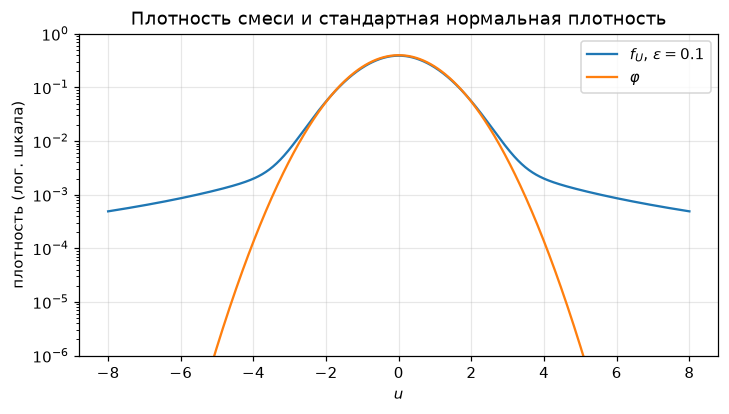

In [4]:
_grid = np.linspace(-8, 8, 801)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(_grid, F.pdf(_grid), label=r"$f_U$, $\varepsilon = 0.1$")
ax.semilogy(_grid, stats.norm.pdf(_grid), label=r"$\varphi$")
ax.set_ylim(1e-6, 1)
ax.set_xlabel("$u$")
ax.set_ylabel("плотность (лог. шкала)")
ax.set_title("Плотность смеси и стандартная нормальная плотность")
ax.legend(loc="upper right")
plt.show()

In [5]:
_x = MU + SIGMA * F.rvs(200, rng_for(1))
pd.Series({
    "среднее": _x.mean(),
    "медиана": np.median(_x),
    "выборочное SD": _x.std(ddof=1),
    "min": _x.min(),
    "max": _x.max(),
    "доля |x − μ| > 4σ": np.mean(np.abs(_x - MU) > 4 * SIGMA),
}, name="выборка n = 200, μ = 3, σ = 2").to_frame()

,"выборка n = 200, μ = 3, σ = 2"
среднее,2.7960
медиана,3.2195
выборочное SD,2.9659
min,-16.7716
max,8.8678
доля |x − μ| > 4σ,0.0150


В выборке около 1.5% наблюдений удалены от центра более чем на $4\sigma$. Выборочное стандартное отклонение заметно превышает $\sigma = 2$, а медиана ближе к $\mu$, чем среднее.

## Функции ψ и ρ

Константы функций Хьюбера, bisquare (биквадратная функция Тьюки), Эндрюса и Уэлша подобраны так, что эффективность при нормальном распределении равна 95%; для функции Хампеля взят стандартный набор $(2, 4, 8)$.

| $\psi$ | вид | параметры |
|---|---|---|
| Хьюбер | $\psi_k(u) = \max(-k, \min(u, k))$ | $k = 1.345$ |
| bisquare | $\psi_c(u) = u\bigl(1 - (u/c)^2\bigr)^2\,\mathbb 1\{\lvert u\rvert \le c\}$ | $c = 4.685$ |
| Хампель | $\psi(u) = \operatorname{sign}(u)\max\bigl\{0, \min\bigl(\lvert u\rvert, a, a\frac{c - \lvert u\rvert}{c - b}\bigr)\bigr\}$ | $(a, b, c) = (2, 4, 8)$ |
| Эндрюс | $\psi_a(u) = a\sin(u/a)\,\mathbb 1\{\lvert u\rvert \le \pi a\}$ | $a = 1.339$ |
| Уэлш | $\psi_c(u) = u\,e^{-(u/c)^2}$ | $c = 2.985$ |

Функции $\rho$ для M-оценок масштаба ограничены и нормированы условиями $\rho(0) = 0$, $\rho(\infty) = 1$:

| $\rho_{\text{scale}}$ | вид |
|---|---|
| bisquare | $\rho_c(u) = 1 - \bigl(1 - (u/c)^2\bigr)^3$ при $\lvert u\rvert \le c$, иначе $1$ |
| Хьюбер | $\rho_c(u) = \min(u^2, c^2)/c^2$ |
| Уэлш | $\rho_c(u) = 1 - e^{-(u/c)^2}$ |

In [6]:
class Psi:
    points = ()

    def weight(self, u):
        safe = np.where(u == 0, 1.0, u)
        return np.where(u == 0, 1.0, self.psi(safe) / safe)


class Huber(Psi):
    def __init__(self, k):
        self.k, self.points = k, (k,)

    def psi(self, u):
        return np.clip(u, -self.k, self.k)

    def dpsi(self, u):
        return np.where(np.abs(u) <= self.k, 1.0, 0.0)


class Bisquare(Psi):
    def __init__(self, c):
        self.c, self.points = c, (c,)

    def psi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, u * (1 - t * t) ** 2, 0.0)

    def dpsi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, (1 - t * t) * (1 - 5 * t * t), 0.0)


class Hampel(Psi):
    def __init__(self, a, b, c):
        self.a, self.b, self.c, self.points = a, b, c, (a, b, c)

    def psi(self, u):
        au = np.abs(u)
        ramp = self.a * (self.c - au) / (self.c - self.b)
        return np.sign(u) * np.where(au < self.a, au, np.where(au < self.b, self.a, np.where(au < self.c, ramp, 0.0)))

    def dpsi(self, u):
        au = np.abs(u)
        slope = -self.a / (self.c - self.b)
        return np.where(au < self.a, 1.0, np.where(au < self.b, 0.0, np.where(au < self.c, slope, 0.0)))


class Andrews(Psi):
    def __init__(self, a):
        self.a, self.points = a, (a * np.pi,)

    def psi(self, u):
        return np.where(np.abs(u) <= self.a * np.pi, self.a * np.sin(u / self.a), 0.0)

    def dpsi(self, u):
        return np.where(np.abs(u) <= self.a * np.pi, np.cos(u / self.a), 0.0)


class Welsch(Psi):
    def __init__(self, c):
        self.c = c

    def psi(self, u):
        return u * np.exp(-((u / self.c) ** 2))

    def dpsi(self, u):
        t2 = (u / self.c) ** 2
        return (1 - 2 * t2) * np.exp(-t2)


class BisquareRho:
    def __init__(self, c):
        self.c, self.points = c, (c,)

    def rho(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, 1 - (1 - t * t) ** 3, 1.0)

    def drho(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, 6 * t / self.c * (1 - t * t) ** 2, 0.0)


class HuberRho:
    def __init__(self, c):
        self.c, self.points = c, (c,)

    def rho(self, u):
        return np.minimum(u * u, self.c**2) / self.c**2

    def drho(self, u):
        return np.where(np.abs(u) <= self.c, 2 * u / self.c**2, 0.0)


class WelschRho:
    def __init__(self, c):
        self.c, self.points = c, ()

    def rho(self, u):
        return 1 - np.exp(-((u / self.c) ** 2))

    def drho(self, u):
        return 2 * u / self.c**2 * np.exp(-((u / self.c) ** 2))


def calibrate(rho_cls, dist, delta=0.5):
    return optimize.brentq(lambda c: dist.expect(rho_cls(c).rho, rho_cls(c).points) - delta, 0.05, 50, xtol=1e-12)


def av_location(psi, dist, theta=1.0):
    pts = [p * theta for p in psi.points]
    num = dist.expect(lambda u: psi.psi(u / theta) ** 2, pts)
    den = dist.expect(lambda u: psi.dpsi(u / theta), pts)
    return theta**2 * num / den**2


def av_mscale(rho, dist, delta):
    num = dist.expect(lambda u: (rho.rho(u) - delta) ** 2, rho.points)
    den = dist.expect(lambda u: rho.drho(u) * u, rho.points)
    return num / den**2


def sandwich(psi, rho, delta, dist):
    pts = tuple(psi.points) + tuple(rho.points)

    def E(g):
        return dist.expect(g, pts)

    A = np.array([
        [E(psi.dpsi), E(lambda u: psi.dpsi(u) * u)],
        [E(rho.drho), E(lambda u: rho.drho(u) * u)],
    ])
    cross = E(lambda u: psi.psi(u) * (rho.rho(u) - delta))
    B = np.array([
        [E(lambda u: psi.psi(u) ** 2), cross],
        [cross, E(lambda u: (rho.rho(u) - delta) ** 2)],
    ])
    A_inv = np.linalg.inv(A)
    return A_inv @ B @ A_inv.T

In [7]:
for _psi in (Huber(1.345), Bisquare(4.685), Andrews(1.339), Welsch(2.985)):
    assert abs(1 / av_location(_psi, N0) - 0.95) < 0.005, type(_psi).__name__
assert abs(calibrate(BisquareRho, N0) - 1.5476) < 1e-3
assert abs(av_location(Huber(1.345), F, 1.1) - av_location(Huber(1.345 * 1.1), F)) < 1e-8
_V = sandwich(Bisquare(4.685), BisquareRho(calibrate(BisquareRho, F)), 0.5, F)
assert abs(_V[0, 1]) < 1e-10 and abs(_V[0, 0] - av_location(Bisquare(4.685), F)) < 1e-8

## 2. Оценки масштаба

$$\mathrm{MADN}(x) = \frac{\operatorname{med}_i\lvert x_i - \operatorname{med}(x)\rvert}{0.6745},\qquad \mathrm{IQRN}(x) = \frac{\hat Q_{0.75}(x) - \hat Q_{0.25}(x)}{1.349}.$$
M-оценка масштаба $\hat s_M$ определяется как решение уравнения
$$\frac1n\sum_{i=1}^n\rho\Bigl(\frac{x_i - \operatorname{med}(x)}{s}\Bigr) = \delta$$
с bisquare-функцией $\rho_c$, $c = 1.5476$, $\delta = 0.5$. Константы $0.6745 = \Phi^{-1}(3/4)$, $1.349 = 2\Phi^{-1}(3/4)$ и пара $(c, \delta)$ обеспечивают состоятельность при нормальном распределении. Точка срыва MADN равна 0.5, IQRN — 0.25, M-оценки — $\min(\delta, 1-\delta) = 0.5$.

### Инвариантность относительно сдвига и эквивариантность относительно масштаба

Оценка масштаба должна удовлетворять условию $\hat\sigma(ax + b) = \lvert a\rvert\,\hat\sigma(x)$ для всех $a \ne 0$, $b \in \mathbb R$.

- MADN: $\operatorname{med}(ax + b) = a\operatorname{med}(x) + b$, поэтому $\lvert ax_i + b - \operatorname{med}(ax + b)\rvert = \lvert a\rvert\,\lvert x_i - \operatorname{med}(x)\rvert$.
- IQRN: при $a > 0$ $\hat Q_p(ax + b) = a\hat Q_p(x) + b$, при $a < 0$ $\hat Q_p(ax + b) = a\hat Q_{1-p}(x) + b$; в обоих случаях разность квартилей умножается на $\lvert a\rvert$.
- M-оценка: остатки $r_i$ переходят в $ar_i$. Если $s$ — решение для $x$, то в силу чётности $\rho$ значение $\lvert a\rvert s$ удовлетворяет уравнению для $ax + b$. Решение единственно, так как левая часть уравнения монотонно убывает по $s$.

Численная проверка (отношение $\hat\sigma(ax + b)/(\lvert a\rvert\hat\sigma(x))$):

In [8]:
def mad_raw(x):
    return np.median(np.abs(x - np.median(x, axis=-1, keepdims=True)), axis=-1)


def iqr_raw(x):
    q1, q3 = np.quantile(x, [0.25, 0.75], axis=-1)
    return q3 - q1


def mscale(r, rho, delta, s0, tol=1e-10, maxit=1000):
    s = np.array(s0, dtype=float)
    for _ in range(maxit):
        s_new = s * np.sqrt(np.mean(rho.rho(r / s[..., None]), axis=-1) / delta)
        done = np.max(np.abs(s_new / s - 1)) < tol
        s = s_new
        if done:
            return s
    raise RuntimeError("M-scale: no convergence")


C_BS_N = calibrate(BisquareRho, N0)
C_BS_F = calibrate(BisquareRho, F)


def madn(x):
    return mad_raw(x) / Q75


def iqrn(x):
    return iqr_raw(x) / (2 * Q75)


def mscale_bisquare(x):
    r = x - np.median(x, axis=-1, keepdims=True)
    return mscale(r, BisquareRho(C_BS_N), 0.5, madn(x))


SCALE_RAW = {"MADN": madn, "IQRN": iqrn, "M-scale": mscale_bisquare}

In [9]:
_x = MU + SIGMA * F.rvs(301, rng_for(21))
_ab =[(-3.7, 11.0), (0.25, -4.0), (1.0, 1e3)]
for _name, _est in SCALE_RAW.items():
    for _a, _b in _ab:
        assert np.isclose(_est(_a * _x + _b), abs(_a) * _est(_x), rtol=1e-8), (_name, _a, _b)
pd.DataFrame({f"a={_a}, b={_b}": {n: e(_a * _x + _b) / (abs(_a) * e(_x)) for n, e in SCALE_RAW.items()} for _a, _b in _ab})

,"a=-3.7, b=11.0","a=0.25, b=-4.0","a=1.0, b=1000.0"
MADN,1.0000,1.0000,1.0000
IQRN,1.0000,1.0000,1.0000
M-scale,1.0000,1.0000,1.0000


### Состоятельность

Все три оценки — непрерывные функционалы от эмпирической функции распределения, поэтому $\hat\sigma \xrightarrow{P} \sigma\,\theta(F_U)$, где $\theta(F_U)$ — значение соответствующего функционала на $F_U$. При симметричном $F_U$ выборочная медиана сходится к $\mu$, и

- MAD: $P(\lvert U\rvert \le m) = 2F_U(m) - 1 = 1/2$, откуда $\operatorname{med}\lvert U\rvert = F_U^{-1}(3/4) =: q_F$ и $\theta_{\mathrm{MAD}} = q_F/\Phi^{-1}(3/4)$;
- IQR: $F_U^{-1}(3/4) - F_U^{-1}(1/4) = 2q_F$, поэтому $\theta_{\mathrm{IQR}} = \theta_{\mathrm{MAD}}$;
- M-оценка: $\theta_M = s_F$, где $s_F$ — решение уравнения $\mathbb E_{F_U}\rho_c(U/s) = \delta$.

Смесь переносит часть массы в хвосты: $F_U\bigl(\Phi^{-1}(3/4)\bigr) \approx 0.744 < 3/4$, откуда $q_F > \Phi^{-1}(3/4)$; аналогично $\mathbb E_{F_U}\rho_c(U) > \delta$, откуда $s_F > 1$. Таким образом, $\theta > 1$: с нормальными константами все три оценки несостоятельны и завышают $\sigma$.

Поскольку $F_U$ известна, оценки можно исправить: $\hat\sigma_{\text{corr}} = \hat\sigma/\theta(F_U)$, т.е. вычислить нормировочные константы по $F_U$ вместо $\Phi$. Для M-оценки это равносильно замене $c$ на $c\,s_F$ (так как $\rho_c(u/s) = \rho_{cs}(u)$); $\delta$ и точка срыва при этом не меняются.

In [10]:
Q_F = F.ppf(0.75)
THETA = {"MADN": Q_F / Q75, "IQRN": Q_F / Q75, "M-scale": C_BS_F / C_BS_N}
SCALE_CORR = {name: (lambda x, est=est, t=THETA[name]: est(x) / t) for name, est in SCALE_RAW.items()}

assert all(t > 1 for t in THETA.values())
_r = _x - np.median(_x)
assert np.isclose(mscale(_r, BisquareRho(C_BS_N), 0.5, madn(_x)) / THETA["M-scale"], mscale(_r, BisquareRho(C_BS_F), 0.5, madn(_x)), rtol=1e-7)
pd.DataFrame({
    "константа для Φ": {"MADN": Q75, "IQRN": 2 * Q75, "M-scale": C_BS_N},
    "константа для F_U": {"MADN": Q_F, "IQRN": 2 * Q_F, "M-scale": C_BS_F},
    "θ(F_U)": THETA,
})

,константа для Φ,константа для F_U,θ(F_U)
MADN,0.6745,0.6945,1.0296
IQRN,1.3490,1.3890,1.0296
M-scale,1.5476,1.6002,1.0340


### Асимптотические дисперсии

При симметричном $F_U$ оценка центра не влияет на асимптотику MADN и M-оценки: $\frac{d}{dt}P(\lvert U - t\rvert \le m)\big|_{t=0} = f_U(m) - f_U(-m) = 0$, а для M-оценки $\mathbb E\rho'(U) = 0$, так как $\rho'$ нечётна (IQRN центр не использует). Функции влияния:

- MAD: $\mathrm{IF}(u) = \dfrac{1/2 - \mathbb 1\{\lvert u\rvert \le q_F\}}{2f_U(q_F)}$, откуда $\mathrm{AV}(\mathrm{MADN}_{\text{corr}}) = \dfrac{\sigma^2}{16\,q_F^2 f_U^2(q_F)}$;
- IQR: $\mathrm{IF}(u) = \dfrac{1/2 - \mathbb 1\{\lvert u\rvert \le q_F\}}{f_U(q_F)}$; после нормировки на $2q_F$ получается та же дисперсия, т.е. при симметричном распределении MADN и IQRN асимптотически эквивалентны;
- M-оценка: $\mathrm{IF}(u) = \dfrac{\rho(u) - \delta}{\mathbb E\rho'(U)U}$, $\mathrm{AV}(\hat s_M) = \sigma^2\dfrac{\mathbb E(\rho(U) - \delta)^2}{(\mathbb E\rho'(U)U)^2}$, где $\rho = \rho_{cs_F}$.

Для проверки: при $F_U = \Phi$ формула для MADN даёт известное значение $1.3605\,\sigma^2$.

In [11]:
def av_quantile_scale(dist):
    q = dist.ppf(0.75)
    return 1 / (16 * q**2 * dist.pdf(q) ** 2)


AV_SCALE = {
    "MADN": av_quantile_scale(F),
    "IQRN": av_quantile_scale(F),
    "M-scale": av_mscale(BisquareRho(C_BS_F), F, 0.5),
}
assert abs(av_quantile_scale(N0) - 1.3605) < 1e-3
pd.Series(AV_SCALE, name="AV(σ̂_corr) / σ²").to_frame()

,AV(σ̂_corr) / σ²
MADN,1.4060
IQRN,1.4060
M-scale,0.9803


### Моделирование

Для $n \in \{50, 200, 1000\}$ генерируется по $R = 5000$ выборок. Сравниваются среднее $\hat\sigma/\sigma$ до и после исправления, а также $n\,\widehat{\operatorname{Var}}(\hat\sigma_{\text{corr}}/\sigma)$ и теоретическая AV.

In [12]:
_rng = rng_for(2)
_rows = []
for n in NS:
    X = MU + SIGMA * F.rvs((R, n), _rng)
    for name, est in SCALE_RAW.items():
        raw = est(X) / SIGMA
        corr = raw / THETA[name]
        _rows.append({
            "n": n,
            "оценка": name,
            "E σ̂/σ, исходная": raw.mean(),
            "E σ̂/σ, исправленная": corr.mean(),
            "n·Var (MC)": n * corr.var(ddof=1),
            "AV (теория)": AV_SCALE[name],
        })
scale_mc = pd.DataFrame(_rows)
_last = scale_mc[scale_mc["n"] == NS[-1]]
assert (abs(_last["E σ̂/σ, исправленная"] - 1) < 0.01).all()
assert (abs(_last["E σ̂/σ, исходная"] - 1) > 0.02).all()
assert (abs(_last["n·Var (MC)"] / _last["AV (теория)"] - 1) < MC_TOL).all()
scale_mc

,n,оценка,"E σ̂/σ, исходная","E σ̂/σ, исправленная",n·Var (MC),AV (теория)
0,50,MADN,1.0135,0.9843,1.3656,1.4060
1,50,IQRN,0.9991,0.9704,1.3084,1.4060
2,50,M-scale,1.0128,0.9795,0.9832,0.9803
3,200,MADN,1.0238,0.9944,1.3732,1.4060
4,200,IQRN,1.0206,0.9912,1.3803,1.4060
5,200,M-scale,1.0272,0.9934,0.9639,0.9803
6,1000,MADN,1.0286,0.9990,1.3629,1.4060
7,1000,IQRN,1.0278,0.9982,1.3597,1.4060
8,1000,M-scale,1.0329,0.9990,0.9494,0.9803


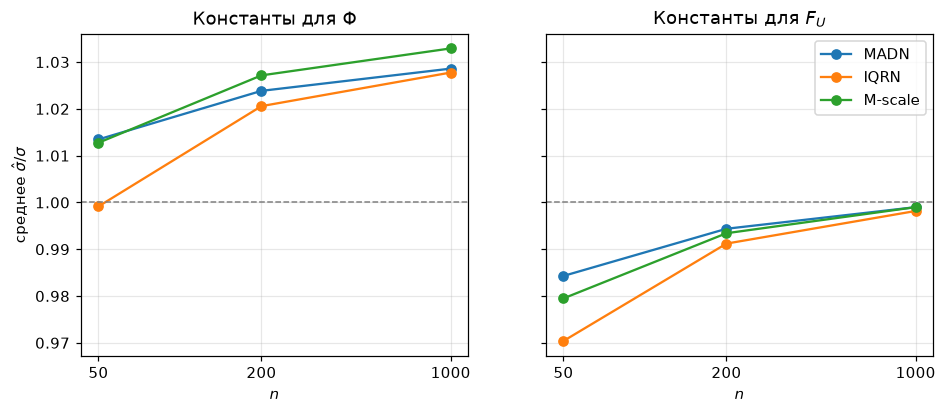

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, col, title in zip(axes, ["E σ̂/σ, исходная", "E σ̂/σ, исправленная"], ["Константы для Φ", "Константы для $F_U$"]):
    for name in SCALE_RAW:
        d = scale_mc[scale_mc["оценка"] == name]
        ax.plot(d["n"], d[col], marker="o", label=name)
    ax.axhline(1, color="gray", lw=1, ls="--")
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(NS, [str(n) for n in NS])
    ax.set_xlabel("$n$")
    ax.set_title(title)
axes[0].set_ylabel(r"среднее $\hat\sigma / \sigma$")
axes[1].legend(loc="upper right")
plt.show()

При $n = 1000$ исправленные оценки практически несмещены, а неисправленные завышают $\sigma$ на 3%, как и предсказывает $\theta(F_U)$. При малых $n$ у всех оценок есть смещение порядка $O(1/n)$: при $n = 50$ исправленные оценки занижают $\sigma$ на 2–3%; близость неисправленной IQRN к единице при $n = 50$ — результат взаимной компенсации двух смещений.

### Выбор оценки

Исправленные оценки состоятельны и эквивариантны. Точка срыва MADN и M-оценки равна 0.5, IQRN — только 0.25. Асимптотическая дисперсия M-оценки ($\approx 0.98\,\sigma^2$) примерно в 1.4 раза меньше, чем у MADN и IQRN ($\approx 1.41\,\sigma^2$). Далее используется исправленная M-оценка масштаба с bisquare-функцией.

In [14]:
SCALE_CHOICE = "M-scale"
assert min(AV_SCALE, key=AV_SCALE.get) == SCALE_CHOICE
sigma_hat = SCALE_CORR[SCALE_CHOICE]

## 3. M-оценки сдвига при оценённом масштабе

Масштаб оценивается заранее (п. 2) и фиксируется; $\hat\mu$ определяется как корень уравнения
$$\sum_{i=1}^n\psi\Bigl(\frac{x_i - \mu}{\hat\sigma}\Bigr) = 0.$$
Уравнение решается методом итеративно перевзвешенных наименьших квадратов (IRLS) с начальным приближением $\operatorname{med}(x)$: $\mu \leftarrow \sum w_ix_i/\sum w_i$, $w_i = \psi(r_i)/r_i$.

### Асимптотика

Линеаризация уравнения в окрестности истинных значений даёт
$$0 \approx \frac1n\sum_{i=1}^n\psi(U_i) - \frac{\hat\mu - \mu}{\sigma}\,\mathbb E\psi'(U) - \frac{\hat\sigma - \sigma}{\sigma}\,\mathbb E\psi'(U)U.$$
Функция $\psi$ нечётна, $F_U$ симметрична, поэтому $\mathbb E\psi'(U)U = 0$, и при состоятельной $\hat\sigma$
$$\sqrt n(\hat\mu - \mu) \Rightarrow N\Bigl(0,\ \sigma^2\frac{\mathbb E\psi^2(U)}{(\mathbb E\psi'(U))^2}\Bigr).$$
Если $\hat\sigma \to \theta\sigma$, то фактически используется функция $\psi(u/\theta)$: $\hat\mu$ остаётся состоятельной, а асимптотическая дисперсия равна $\sigma^2\theta^2\,\mathbb E\psi^2(U/\theta)/(\mathbb E\psi'(U/\theta))^2$.

Для функции Хьюбера $\psi_k'(u) = \mathbb 1\{\lvert u\rvert \le k\}$, и ожидания вычисляются явно:
$$\mathbb E\psi_k'(U) = (1-\varepsilon)\bigl(2\Phi(k) - 1\bigr) + \varepsilon\,\frac2\pi\operatorname{arctg}k,$$
$$\mathbb E\psi_k^2(U) = (1-\varepsilon)\bigl(2\Phi(k) - 1 - 2k\varphi(k)\bigr) + \varepsilon\,\frac2\pi\bigl(k - \operatorname{arctg}k\bigr) + k^2P(\lvert U\rvert > k).$$
Для bisquare ожидания вычисляются численно. Для сравнения: у медианы $\mathrm{AV} = \sigma^2/(4f_U^2(0))$, у среднего $\mathrm{AV} = \infty$.

In [15]:
def av_huber_exact(k, eps=EPS):
    p_in = (1 - eps) * (2 * stats.norm.cdf(k) - 1) + eps * 2 / np.pi * np.arctan(k)
    m2_in = (1 - eps) * (2 * stats.norm.cdf(k) - 1 - 2 * k * stats.norm.pdf(k)) + eps * 2 / np.pi * (k - np.arctan(k))
    return (m2_in + k**2 * (1 - p_in)) / p_in**2


def m_location(x, psi, s, tol=1e-10, maxit=1000):
    s = np.asarray(s, dtype=float)[..., None]
    mu = np.median(x, axis=-1)
    for _ in range(maxit):
        w = psi.weight((x - mu[..., None]) / s)
        mu_new = np.sum(w * x, axis=-1) / np.sum(w, axis=-1)
        done = np.max(np.abs(mu_new - mu) / s[..., 0]) < tol
        mu = mu_new
        if done:
            return mu
    raise RuntimeError("M-location: no convergence")


HUBER_KS = (0.5, 1.0, 1.345, 1.5, 2.0)
BISQ_CS = (3.0, 4.0, 4.685, 6.0)
LOC_GRID = {f"Huber k={k}": Huber(k) for k in HUBER_KS} | {f"bisquare c={c}": Bisquare(c) for c in BISQ_CS}
AV_MEDIAN = 1 / (4 * F.pdf(0.0) ** 2)

for _k in HUBER_KS:
    assert abs(av_huber_exact(_k) - av_location(Huber(_k), F)) < 1e-8
_x = MU + SIGMA * F.rvs(301, rng_for(31))
for _psi in (Huber(1.345), Bisquare(4.685)):
    for _a, _b in [(-3.7, 11.0), (0.25, -4.0)]:
        _y = _a * _x + _b
        assert np.isclose(m_location(_y, _psi, sigma_hat(_y)), _a * m_location(_x, _psi, sigma_hat(_x)) + _b, rtol=1e-8, atol=1e-7)

In [16]:
av_loc = pd.DataFrame({
    "AV/σ² при F_U": {name: av_location(psi, F) for name, psi in LOC_GRID.items()},
    "эффективность при Φ": {name: 1 / av_location(psi, N0) for name, psi in LOC_GRID.items()},
})
av_loc.loc["медиана"] = [AV_MEDIAN, 2 / np.pi]
av_loc.loc["среднее"] = [np.inf, 1.0]
av_loc

,AV/σ² при F_U,эффективность при Φ
Huber k=0.5,1.3326,0.7921
Huber k=1.0,1.1963,0.9031
Huber k=1.345,1.1591,0.9500
Huber k=1.5,1.1526,0.9642
Huber k=2.0,1.1613,0.9897
bisquare c=3.0,1.3518,0.7727
bisquare c=4.0,1.1638,0.9100
bisquare c=4.685,1.1239,0.9500
bisquare c=6.0,1.1066,0.9810
медиана,1.6363,0.6366


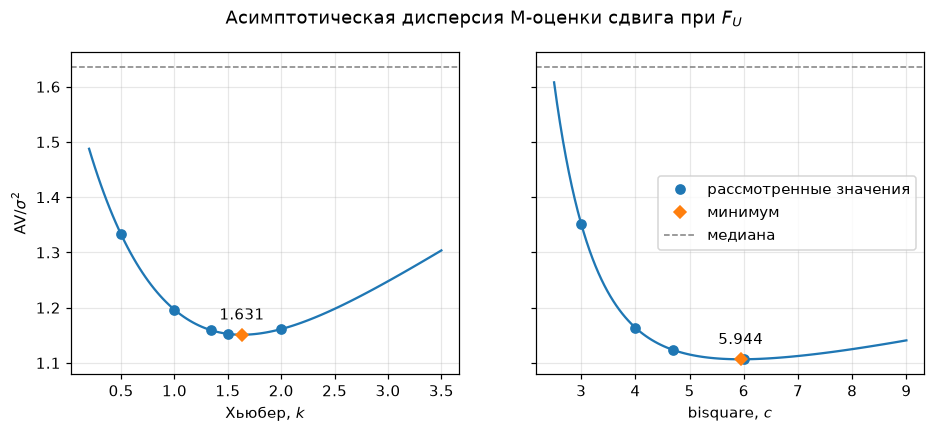

,значение
k*,1.6312
AV(k*),1.1510
c*,5.9438
AV(c*),1.1066


In [17]:
K_OPT = optimize.minimize_scalar(av_huber_exact, bounds=(0.1, 4.0), method="bounded", options={"xatol": 1e-6}).x
C_OPT = optimize.minimize_scalar(lambda c: av_location(Bisquare(c), F), bounds=(2.0, 10.0), method="bounded", options={"xatol": 1e-6}).x

_panels = [
    (np.linspace(0.2, 3.5, 120), av_huber_exact, HUBER_KS, K_OPT, "Хьюбер, $k$"),
    (np.linspace(2.5, 9.0, 120), lambda c: av_location(Bisquare(c), F), BISQ_CS, C_OPT, "bisquare, $c$"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (grid, fn, pts, opt, xlabel) in zip(axes, _panels):
    ax.plot(grid, [fn(g) for g in grid], color="C0")
    ax.plot(pts, [fn(p) for p in pts], "o", color="C0", label="рассмотренные значения")
    ax.plot([opt], [fn(opt)], "D", color="C1", label="минимум")
    ax.annotate(f"{opt:.3f}", (opt, fn(opt)), textcoords="offset points", xytext=(0, 10), ha="center")
    ax.axhline(AV_MEDIAN, color="gray", ls="--", lw=1, label="медиана")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel(r"$\mathrm{AV} / \sigma^2$")
axes[1].legend(loc="center right")
fig.suptitle("Асимптотическая дисперсия M-оценки сдвига при $F_U$")
plt.show()
pd.Series({"k*": K_OPT, "AV(k*)": av_huber_exact(K_OPT), "c*": C_OPT, "AV(c*)": av_location(Bisquare(C_OPT), F)}).to_frame("значение")

Асимптотическая дисперсия при несостоятельной оценке масштаба (без исправления из п. 2):

In [18]:
_theta = THETA[SCALE_CHOICE]
pd.DataFrame({
    "σ̂ состоятельна": {name: av_location(psi, F) for name, psi in LOC_GRID.items()},
    f"σ̂ → {_theta:.4f}σ": {name: av_location(psi, F, _theta) for name, psi in LOC_GRID.items()},
}).rename_axis("AV/σ²")

,σ̂ состоятельна,σ̂ → 1.0340σ
AV/σ²,,
Huber k=0.5,1.3326,1.3258
Huber k=1.0,1.1963,1.1910
Huber k=1.345,1.1591,1.1566
Huber k=1.5,1.1526,1.1516
Huber k=2.0,1.1613,1.1650
bisquare c=3.0,1.3518,1.3190
bisquare c=4.0,1.1638,1.1527
bisquare c=4.685,1.1239,1.1190
bisquare c=6.0,1.1066,1.1070


Несостоятельность $\hat\sigma$ влияет на AV слабо: она лишь увеличивает константу настройки в $\theta$ раз.

### Моделирование

Для каждой выборки вычисляется $\hat\sigma$ (п. 2), затем $\hat\mu$ для всех функций из сетки, медиана и среднее. В таблице — $n\,\widehat{\operatorname{Var}}(\hat\mu)/\sigma^2$ при разных $n$, теоретическая AV и смещение $\hat\mu$ при $n = 1000$.

In [19]:
_rng = rng_for(3)
_rows = []
for n in NS:
    X = MU + SIGMA * F.rvs((R, n), _rng)
    s = sigma_hat(X)
    fits = {name: m_location(X, psi, s) for name, psi in LOC_GRID.items()}
    fits["медиана"] = np.median(X, axis=-1)
    fits["среднее"] = X.mean(axis=-1)
    for name, mu_hat in fits.items():
        _rows.append({
            "n": n,
            "оценка": name,
            "смещение": mu_hat.mean() - MU,
            "n·Var/σ² (MC)": n * mu_hat.var(ddof=1) / SIGMA**2,
            "AV/σ² (теория)": av_loc.loc[name, "AV/σ² при F_U"],
        })
loc_mc = pd.DataFrame(_rows)
_last = loc_mc[(loc_mc["n"] == NS[-1]) & (loc_mc["оценка"] != "среднее")]
assert (abs(_last["n·Var/σ² (MC)"] / _last["AV/σ² (теория)"] - 1) < MC_TOL).all()
assert (abs(_last["смещение"]) < 4 * SIGMA * np.sqrt(_last["AV/σ² (теория)"] / (NS[-1] * R))).all()
_tab = loc_mc.pivot(index="оценка", columns="n", values="n·Var/σ² (MC)")
_tab.columns = [f"n·Var/σ², n={n}" for n in _tab.columns]
_tab["AV/σ²"] = av_loc["AV/σ² при F_U"]
_tab[f"смещение, n={NS[-1]}"] = loc_mc[loc_mc["n"] == NS[-1]].set_index("оценка")["смещение"]
_tab.loc[list(av_loc.index)]

,"n·Var/σ², n=50","n·Var/σ², n=200","n·Var/σ², n=1000",AV/σ²,"смещение, n=1000"
оценка,,,,,
Huber k=0.5,1.3418,1.2867,1.3240,1.3326,-0.0025
Huber k=1.0,1.2118,1.1479,1.2076,1.1963,-0.0022
Huber k=1.345,1.1795,1.1119,1.1730,1.1591,-0.0021
Huber k=1.5,1.1769,1.1064,1.1647,1.1526,-0.0020
Huber k=2.0,1.1969,1.1173,1.1648,1.1613,-0.0021
bisquare c=3.0,1.3621,1.3061,1.3770,1.3518,-0.0022
bisquare c=4.0,1.1732,1.1205,1.1878,1.1638,-0.0020
bisquare c=4.685,1.1325,1.0810,1.1465,1.1239,-0.0020
bisquare c=6.0,1.1207,1.0642,1.1261,1.1066,-0.0019


### Выбор оценки

Среднее непригодно: его дисперсия бесконечна при любом $n$, и выборочные значения в таблице неустойчивы. Медиана робастна, но её асимптотическая дисперсия велика ($\approx 1.64\,\sigma^2$). Все M-оценки практически несмещены. Минимум AV для функции Хьюбера достигается при $k^* \approx 1.63$ ($\approx 1.151\,\sigma^2$), для bisquare — при $c^* \approx 5.94$ ($\approx 1.107\,\sigma^2$). Даже при оптимальном $k$ оценка Хьюбера уступает bisquare: $\psi_k$ не убывает к нулю при $\lvert u\rvert \to \infty$, и далёкие наблюдения из компоненты Коши вносят в $\mathbb E\psi^2$ вклад $k^2$, тогда как у bisquare они получают нулевой вес.

Выбрана оценка bisquare с $c = 6$: её асимптотическая дисперсия совпадает с минимальной с точностью до $10^{-4}$, эффективность при нормальном распределении около 98%. При стандартном $c = 4.685$ асимптотическая дисперсия больше примерно на 1.5%, но удалённые наблюдения отбрасываются раньше, что может быть предпочтительнее при более сильном засорении. Оценка требует хорошего начального приближения и робастной оценки масштаба; здесь это медиана и M-оценка масштаба с точкой срыва 0.5.

In [20]:
LOC_CHOICE = "bisquare c=6.0"
assert abs(av_loc.loc[LOC_CHOICE, "AV/σ² при F_U"] / av_location(Bisquare(C_OPT), F) - 1) < 1e-3

## 4. Совместное оценивание μ и σ

Параметры находятся из системы
$$\frac1n\sum_{i=1}^n\psi\Bigl(\frac{x_i - \mu}{\sigma}\Bigr) = 0,\qquad \frac1n\sum_{i=1}^n\rho\Bigl(\frac{x_i - \mu}{\sigma}\Bigr) = \delta.$$
Рассматриваются две схемы:
- Huber Proposal 2: $\psi = \psi_k$, $k = 1.345$, $\rho = \psi_k^2/k^2$, $\delta = \beta/k^2$, где $\beta = \mathbb E_{F_U}\psi_k^2(U)$ (в исходном варианте $\beta$ вычисляется по $\Phi$; калибровка по $F_U$ обеспечивает состоятельность $\hat\sigma$);
- bisquare для сдвига ($c = 6$, выбрана в п. 3) и bisquare M-оценка масштаба с константой, откалиброванной по $F_U$, $\delta = 0.5$.

Система решается попеременными итерациями: $s \leftarrow s\sqrt{\overline{\rho(r/s)}/\delta}$, затем шаг IRLS для $\mu$.

### Асимптотическая ковариация

Для $\vartheta = (\mu, \sigma)$ и $\Psi(x; \vartheta) = \bigl(\psi(r), \rho(r) - \delta\bigr)$, $r = (x - \mu)/\sigma$, имеем $\sqrt n(\hat\vartheta - \vartheta) \Rightarrow N(0, \sigma^2V)$, $V = A^{-1}BA^{-\top}$, где
$$A = \begin{pmatrix}\mathbb E\psi'(U) & \mathbb E\psi'(U)U\\ \mathbb E\rho'(U) & \mathbb E\rho'(U)U\end{pmatrix},\qquad B = \begin{pmatrix}\mathbb E\psi^2(U) & \mathbb E\psi(U)(\rho(U) - \delta)\\ \mathbb E\psi(U)(\rho(U) - \delta) & \mathbb E(\rho(U) - \delta)^2\end{pmatrix}.$$
Функции $\psi'$ и $\rho$ чётны, а $\psi$ и $\rho'$ нечётны, поэтому при симметричном $F_U$ $\mathbb E\psi'(U)U = \mathbb E\rho'(U) = \mathbb E\psi(U)(\rho(U) - \delta) = 0$. Матрица $V$ диагональна, $\hat\mu$ и $\hat\sigma$ асимптотически независимы, а диагональные элементы совпадают с асимптотическими дисперсиями соответствующих раздельных оценок. Асимптотически совместное оценивание не отличается от раздельного; различие проявляется в робастности.

Точка срыва M-оценки масштаба с ограниченной $\rho$, $\rho(\infty) = 1$, при фиксированном центре равна $\min(\delta, 1 - \delta)$. В совместной схеме с монотонной $\psi$ выбросы смещают и $\hat\mu$. Для Proposal 2 пусть доля $p$ наблюдений уходит в бесконечность, а $\hat\sigma \to \infty$ так, что нормированные остатки остальных наблюдений стремятся к $a$, $\lvert a\rvert \le k$. Тогда уравнения принимают вид $(1-p)a + pk = 0$ и $(1-p)a^2/k^2 + p = \delta$, откуда $p/(1-p) = \delta$, т.е. точка срыва равна $\delta/(1+\delta)$.

In [21]:
K_P2 = 1.345
BETA = F.expect(lambda u: Huber(K_P2).psi(u) ** 2, (K_P2,))


def m_joint(x, psi, rho, delta, tol=1e-10, maxit=2000):
    mu = np.median(x, axis=-1)
    s = madn(x)
    for _ in range(maxit):
        s_new = s * np.sqrt(np.mean(rho.rho((x - mu[..., None]) / s[..., None]), axis=-1) / delta)
        w = psi.weight((x - mu[..., None]) / s_new[..., None])
        mu_new = np.sum(w * x, axis=-1) / np.sum(w, axis=-1)
        done = max(np.max(np.abs(mu_new - mu) / s_new), np.max(np.abs(s_new / s - 1))) < tol
        mu, s = mu_new, s_new
        if done:
            return mu, s
    raise RuntimeError("joint M-estimator: no convergence")


JOINT = {
    "Proposal 2": (Huber(K_P2), HuberRho(K_P2), BETA / K_P2**2),
    "bisquare + M-scale": (LOC_GRID[LOC_CHOICE], BisquareRho(C_BS_F), 0.5),
}
JOINT_V = {name: sandwich(psi, rho, delta, F) for name, (psi, rho, delta) in JOINT.items()}

_x = MU + SIGMA * F.rvs(301, rng_for(41))
for _name, (_psi, _rho, _delta) in JOINT.items():
    _m, _s = m_joint(_x, _psi, _rho, _delta)
    _my, _sy = m_joint(-3.7 * _x + 11.0, _psi, _rho, _delta)
    assert np.isclose(_my, -3.7 * _m + 11.0, rtol=1e-8, atol=1e-7) and np.isclose(_sy, 3.7 * _s, rtol=1e-8), _name
    assert abs(JOINT_V[_name][0, 1]) < 1e-10

pd.DataFrame({
    name: {"δ": delta, "точка срыва масштаба при фикс. центре": min(delta, 1 - delta), "V_μμ": V[0, 0], "V_σσ": V[1, 1], "V_μσ": V[0, 1]}
    for (name, (_, _, delta)), V in zip(JOINT.items(), JOINT_V.values())
})

,Proposal 2,bisquare + M-scale
δ,0.4086,0.5000
точка срыва масштаба при фикс. центре,0.4086,0.5000
V_μμ,1.1591,1.1066
V_σσ,0.8481,0.9803
V_μσ,0.0000,0.0000


### Моделирование

In [22]:
_rng = rng_for(4)
_rows = []
for n in NS:
    X = MU + SIGMA * F.rvs((R, n), _rng)
    for name, (psi, rho, delta) in JOINT.items():
        mu_hat, s_hat = m_joint(X, psi, rho, delta)
        V = JOINT_V[name]
        _rows.append({
            "n": n,
            "схема": name,
            "E σ̂/σ": s_hat.mean() / SIGMA,
            "n·Var μ̂/σ² (MC)": n * mu_hat.var(ddof=1) / SIGMA**2,
            "V_μμ": V[0, 0],
            "n·Var σ̂/σ² (MC)": n * s_hat.var(ddof=1) / SIGMA**2,
            "V_σσ": V[1, 1],
            "n·Cov/σ² (MC)": n * np.cov(mu_hat, s_hat)[0, 1] / SIGMA**2,
        })
joint_mc = pd.DataFrame(_rows)
_last = joint_mc[joint_mc["n"] == NS[-1]]
assert (abs(_last["n·Var μ̂/σ² (MC)"] / _last["V_μμ"] - 1) < MC_TOL).all()
assert (abs(_last["n·Var σ̂/σ² (MC)"] / _last["V_σσ"] - 1) < MC_TOL).all()
assert (abs(_last["n·Cov/σ² (MC)"]) < 4 * np.sqrt(_last["V_μμ"] * _last["V_σσ"] / R)).all()
assert (abs(_last["E σ̂/σ"] - 1) < 0.01).all()
joint_mc

,n,схема,E σ̂/σ,n·Var μ̂/σ² (MC),V_μμ,n·Var σ̂/σ² (MC),V_σσ,n·Cov/σ² (MC)
0,50,Proposal 2,0.9902,1.2038,1.1591,0.8305,0.8481,0.0041
1,50,bisquare + M-scale,0.9930,1.1593,1.1066,0.9487,0.9803,0.0046
2,200,Proposal 2,0.9967,1.1536,1.1591,0.8097,0.8481,-0.0139
3,200,bisquare + M-scale,0.9974,1.0912,1.1066,0.9482,0.9803,-0.0107
4,1000,Proposal 2,1.0004,1.1524,1.1591,0.8777,0.8481,-0.0204
5,1000,bisquare + M-scale,1.0005,1.1077,1.1066,1.0213,0.9803,-0.0243


### Проверка точки срыва

В выборке объёма $n = 200$ доля $p$ наблюдений заменяется на $10^4$, после чего вычисляется $\hat\sigma$.

In [23]:
_x0 = MU + SIGMA * F.rvs(200, rng_for(42))
_rows = {}
for p in (0.0, 0.1, 0.2, 0.3, 0.35, 0.4, 0.45):
    x = _x0.copy()
    x[: int(round(p * len(x)))] = 1e4
    row = {name: m_joint(x, *spec)[1] for name, spec in JOINT.items()}
    row["M-scale из п. 2"] = sigma_hat(x)
    _rows[p] = row
breakdown = pd.DataFrame(_rows).T.rename_axis("p")
BP_P2 = JOINT["Proposal 2"][2] / (1 + JOINT["Proposal 2"][2])
assert 0.2 < BP_P2 < 0.3
assert breakdown.loc[0.2, "Proposal 2"] < 10 * SIGMA and breakdown.loc[0.3, "Proposal 2"] > 100 * SIGMA
assert (breakdown[["bisquare + M-scale", "M-scale из п. 2"]] < 10 * SIGMA).all().all()
breakdown

,Proposal 2,bisquare + M-scale,M-scale из п. 2
p,,,
0.0000,1.9042,1.9262,1.9174
0.1000,2.2936,2.2254,2.2584
0.2000,3.2434,2.7315,2.9044
0.3000,5328.8407,3.4302,4.0207
0.3500,5546.4359,4.0214,5.0496
0.4000,5696.7335,5.0691,7.3904
0.4500,5785.1248,7.2423,13.5248


Оценка масштаба в Proposal 2 разрушается между $p = 0.2$ и $p = 0.3$, что согласуется с точкой срыва $\delta/(1+\delta) \approx 0.29$. У схем с $\delta = 0.5$ оценка $\hat\sigma$ растёт, но остаётся ограниченной вплоть до $p = 0.45$.